In [97]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

from sklearn.linear_model import LinearRegression, QuantileRegressor, LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import r2_score

sns.set_theme(style="darkgrid")

Oefening 1.1: Lees met pd.read_csv het bestand ../data/uber_2025.csv in. Deze bevat 2000 (willekeurig gekozen) uber ritten in New York in Januari 2025. Maak een scatterplot van 'base_passenger_fare' t.o.v. 'trip_miles'.

In [51]:
uber_df_2025 = pd.read_csv('../../data/uber_2025.csv') # Adjust path to file location

In [52]:
uber_df_2025.sample(5)

,app_used,ride_id,request_datetime,on_scene_datetime,pickup_datetime,dropoff_datetime,pickup_zone_id,dropoff_zone_id,trip_miles,trip_seconds,base_passenger_fare,tolls,sales_tax,tips,driver_pay
750,Uber,15367166,2025-01-24 16:13:31,2025-01-24 16:14:34,2025-01-24 16:15:58,2025-01-24 16:34:22,212,60,2.09,1104,12.78,0.00,1.13,0.0,13.57
1855,Uber,18275237,2025-01-28 21:20:07,2025-01-28 21:20:36,2025-01-28 21:20:47,2025-01-28 21:48:46,238,95,13.44,1679,36.52,6.94,3.86,0.0,34.59
400,Uber,14742700,2025-01-23 18:13:48,2025-01-23 18:15:07,2025-01-23 18:16:06,2025-01-23 18:28:20,95,95,1.33,734,11.92,0.00,1.06,0.0,8.94
1748,Uber,9498015,2025-01-15 23:36:02,2025-01-15 23:38:10,2025-01-15 23:39:18,2025-01-16 00:12:54,114,89,10.46,2016,49.44,0.00,4.39,10.0,33.82
1548,Uber,625963,2025-01-01 22:20:17,2025-01-01 22:38:21,2025-01-01 22:38:49,2025-01-01 22:54:25,208,92,6.77,936,17.38,6.94,2.22,0.0,22.55


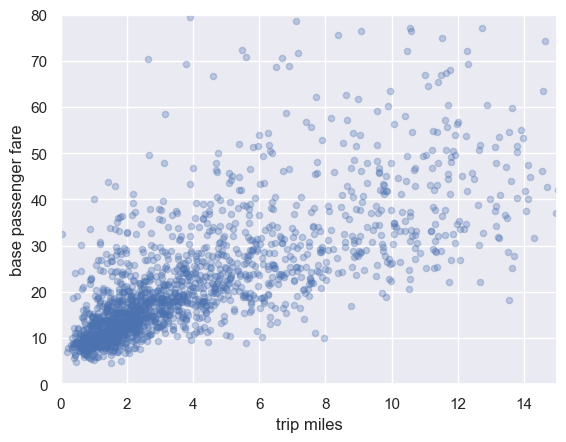

In [53]:
fig, ax = plt.subplots()

ax.scatter(
        uber_df_2025['trip_miles'], 
        uber_df_2025['base_passenger_fare'], 
        alpha=0.3,           
        s=20         
    )


ax.set_xlim(0, 15)
ax.set_ylim(0,80)


ax.set_xlabel('trip miles', fontsize=12)
ax.set_ylabel('base passenger fare', fontsize=12)

plt.show()

Oefening 1.2: Train met sklearn.LinearRegression een model dat de base_passenger_fare uit de trip_miles voorspelt.
Plot deze voorspelling bovenop de scatterplot uit 1.1. 
Gebruik sklearn.metrics.r2_score(df['base_passenger_fare'], df['jouw_voorspelling']) om in te schatten hoe goed je voorspelling is. 

Hint: Zorg bij het maken van een lijnplot er voor dat de datapunten in de juiste volgorde staan...

a=[[3.05838518]], b=[9.60056976]
r2 score: 0.6921048040435018


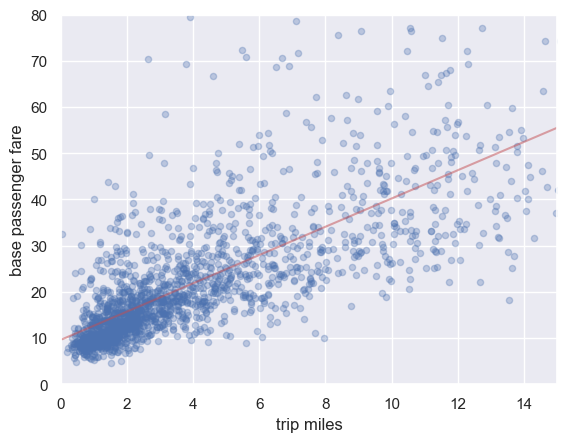

In [54]:
lr_model = LinearRegression()
lr_model.fit(uber_df_2025[['trip_miles']], uber_df_2025[['base_passenger_fare']])

print(f"a={lr_model.coef_}, b={lr_model.intercept_}")

uber_df_with_predictions =  (
                                uber_df_2025
                                .assign(model_prediction = lambda df: lr_model.predict(df[['trip_miles']]))
                                .sort_values("trip_miles")
)

print(f"r2 score: {r2_score(uber_df_with_predictions['base_passenger_fare'], uber_df_with_predictions['model_prediction'])}")
    
fig, ax = plt.subplots()

ax.scatter(
        uber_df_2025['trip_miles'], 
        uber_df_2025['base_passenger_fare'], 
        alpha=0.3,          
        s=20             
    )

ax.plot(
        uber_df_with_predictions['trip_miles'],
        uber_df_with_predictions['model_prediction'],
        'r',
        alpha = 0.5
    )

ax.set_xlim(0, 15)
ax.set_ylim(0,80)

ax.set_xlabel('trip miles', fontsize=12)
ax.set_ylabel('base passenger fare', fontsize=12)

plt.show()

Oefening 1.3: Herhaal oefening 1.2 met als model sklearn.RandomForestRegressor() . Wat valt je op? Doet dit model het beter dan de lineaire regressie?

c:\Users\testadmin\Documents\repos\data-analytics-course-python\.venv\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


r2 score: 0.8825079580613994


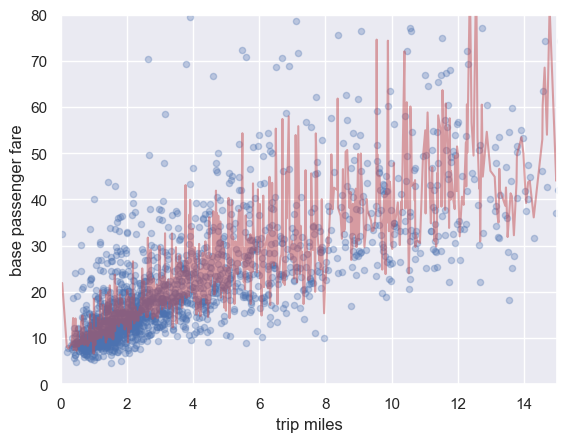

In [55]:
rf_model = RandomForestRegressor()
rf_model.fit(uber_df_2025[['trip_miles']], uber_df_2025[['base_passenger_fare']])

uber_df_with_predictions = (
                                uber_df_2025
                                .assign(model_prediction = lambda df: rf_model.predict(df[['trip_miles']]))
                                .sort_values("trip_miles")
)

print(f"r2 score: {r2_score(uber_df_with_predictions['base_passenger_fare'], uber_df_with_predictions['model_prediction'])}")


fig, ax = plt.subplots()

ax.scatter(
    uber_df_2025['trip_miles'], 
    uber_df_2025['base_passenger_fare'], 
    alpha=0.3,          
    s=20             
    )

ax.plot(
    uber_df_with_predictions['trip_miles'],
    uber_df_with_predictions['model_prediction'],
    'r',
    alpha = 0.5
    )

ax.set_xlim(0, 15)
ax.set_ylim(0,80)

ax.set_xlabel('trip miles', fontsize=12)
ax.set_ylabel('base passenger fare', fontsize=12)

plt.show()


Oefening 1.4: Naar productie! Lees ../data/uber_X_2026.csv in en maak voorspellingen van de passenger_fare op basis van jou in 1.2 en 1.3 getrainede lineaire regressie en random forest model. Welk model zou jij je stakeholders aanraden om te gebruiken? 

In [56]:
uber_X_2026 = pd.read_csv('../../data/uber_X_2026.csv') # Adjust path to file location
uber_X_2026

,ride_id,request_datetime,pickup_zone_id,dropoff_zone_id,trip_miles
0,19417210,2026-01-30 09:18:03,241,161,10.96
1,5204124,2026-01-09 15:05:39,185,18,3.01
2,3674288,2026-01-07 00:30:00,234,229,2.86
3,16315866,2026-01-25 01:16:38,37,17,2.08
4,7362081,2026-01-12 13:38:06,7,196,5.72
...,...,...,...,...,...
9995,494836,2026-01-01 15:19:59,79,170,1.98
9996,20679598,2026-01-31 18:41:50,230,158,2.90
9997,17870438,2026-01-28 09:40:46,233,234,2.61
9998,17745208,2026-01-28 05:27:19,216,132,2.72


In [57]:
uber_X_2026_with_predictions = uber_X_2026.assign(
    lr_prediction = lambda df: lr_model.predict(df[['trip_miles']]),
    rf_prediction = lambda df: rf_model.predict(df[['trip_miles']]),
)

uber_X_2026_with_predictions.sample(10)

,ride_id,request_datetime,pickup_zone_id,dropoff_zone_id,trip_miles,lr_prediction,rf_prediction
5306,13520456,2026-01-21 13:03:00,162,265,6.71,30.122334,37.804611
9525,13227423,2026-01-21 03:40:58,189,190,1.50,14.188148,12.160155
7582,1528041,2026-01-03 11:09:21,91,265,30.21,101.994386,93.501100
2234,1103649,2026-01-02 17:33:04,76,37,5.44,26.238185,35.224313
166,2031963,2026-01-04 02:25:46,80,232,2.42,17.001862,18.659481
8966,5594766,2026-01-10 01:02:25,236,239,1.67,14.708073,16.137199
8245,17149806,2026-01-27 07:58:26,181,246,7.22,31.682111,26.737773
918,7409320,2026-01-12 15:31:11,228,14,1.03,12.750706,10.908446
3781,1726836,2026-01-03 17:49:49,218,10,0.95,12.506036,11.031803
3596,15405464,2026-01-24 00:39:58,45,137,2.33,16.726607,14.902130


Oefening 1.5: Laten we bekijken hoe goed de modellen het gedaan hebben. Lees ..data/uber_y_2026.csv in en bereken de r2 score van je voorspellingen, voor zowel de lineaire regressie als de random forest, met r2_score(df['base_passenger_fare'], df['jouw_voorspelling']). Hoe kan dit? Hoe had je dit van te voren kunnen weten?

In [58]:
uber_Y_2026 =  pd.read_csv('../../data/uber_Y_2026.csv')
uber_Y_2026

,ride_id,base_passenger_fare
0,19417210,41.78
1,5204124,15.78
2,3674288,18.76
3,16315866,17.01
4,7362081,23.66
...,...,...
9995,494836,8.97
9996,20679598,26.68
9997,17870438,33.21
9998,17745208,17.05


In [59]:
uber_df_2026_with_predictions = uber_X_2026_with_predictions.merge(uber_Y_2026, on = 'ride_id')
uber_df_2026_with_predictions

,ride_id,request_datetime,pickup_zone_id,dropoff_zone_id,trip_miles,lr_prediction,rf_prediction,base_passenger_fare
0,19417210,2026-01-30 09:18:03,241,161,10.96,43.120471,50.409800,41.78
1,5204124,2026-01-09 15:05:39,185,18,3.01,18.806309,21.501007,15.78
2,3674288,2026-01-07 00:30:00,234,229,2.86,18.347551,15.060467,18.76
3,16315866,2026-01-25 01:16:38,37,17,2.08,15.962011,15.406900,17.01
4,7362081,2026-01-12 13:38:06,7,196,5.72,27.094533,24.970090,23.66
...,...,...,...,...,...,...,...,...
9995,494836,2026-01-01 15:19:59,79,170,1.98,15.656172,18.951130,8.97
9996,20679598,2026-01-31 18:41:50,230,158,2.90,18.469887,21.604678,26.68
9997,17870438,2026-01-28 09:40:46,233,234,2.61,17.582955,19.531346,33.21
9998,17745208,2026-01-28 05:27:19,216,132,2.72,17.919377,22.058462,17.05


In [60]:
print(f"R2 score linear regression: {r2_score(uber_df_2026_with_predictions['base_passenger_fare'], uber_df_2026_with_predictions['lr_prediction'])}")
print(f"R2 score random forest: {r2_score(uber_df_2026_with_predictions['base_passenger_fare'], uber_df_2026_with_predictions['rf_prediction'])}")

R2 score linear regression: 0.6662885702941643
R2 score random forest: 0.575812815930898


Oefening 1.6: Splits de dataset uit 2025 met onderstaande code in een 'train' (80% v.d. data) en een 'test' (20% v.d. data) set. Train dezelfde modellen als in 1.2-1.3, maar doe dit enkel op de train set. Doe vervolgende een voorspelling op de test set en bereken op deze test set de r2 score. Is dit denk je een goede inschatting van hoe de modellen in productie presteren? 

In [61]:
from sklearn.model_selection import train_test_split

In [62]:
uber_df_2025 = pd.read_csv('../../data/uber_2025.csv') # Adjust path to file location
train_set, test_set =  train_test_split(uber_df_2025, test_size = 0.2)

In [65]:
lr_model, rf_model = LinearRegression(), RandomForestRegressor()
lr_model.fit(train_set[['trip_miles']], train_set[['base_passenger_fare']])
rf_model.fit(train_set[['trip_miles']], train_set[['base_passenger_fare']])

test_set_with_predictions = test_set.assign(
    lr_prediction = lambda df: lr_model.predict(df[['trip_miles']]),
    rf_prediction = lambda df: rf_model.predict(df[['trip_miles']]),
)

print(f"R2 score linear regression: {r2_score(test_set_with_predictions['base_passenger_fare'], test_set_with_predictions['lr_prediction'])}")
print(f"R2 score random forest: {r2_score(test_set_with_predictions['base_passenger_fare'], test_set_with_predictions['rf_prediction'])}")

c:\Users\testadmin\Documents\repos\data-analytics-course-python\.venv\Lib\site-packages\sklearn\base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


R2 score linear regression: 0.7494217293720964
R2 score random forest: 0.5973985828736263


Bonus: Oefening 1.7: Herhaal 1.2-1.3 met een sklearn.model.QuantileRegressor. Doet deze het beter dan de lineaire regressie? Met welke loss functie moet je dit meten? Verandere het quantile argument en bekijk hoe de plot verandert.

Bonus: Oefening 1.8: Gebruik een bootstrap confidence interval om de foutmarge om de op de testset (in 1.6) berekende r2 score in te schatten. Wat zegt dit?

In [66]:
from scipy.stats import bootstrap

In [71]:
rng = np.random.default_rng(seed = 42)

In [ ]:
lr_data = [test_set_with_predictions['base_passenger_fare'].to_numpy(),test_set_with_predictions['lr_prediction'].to_numpy()]
bootstrap(lr_data, lambda base_passenger_fare, lr_prediction: r2_score(base_passenger_fare, lr_prediction), confidence_level=0.95, random_state = rng, paired=True).confidence_interval

ConfidenceInterval(low=np.float64(0.6821481479586451), high=np.float64(0.8310021245645888))

In [76]:
rf_data = [test_set_with_predictions['base_passenger_fare'].to_numpy(),test_set_with_predictions['rf_prediction'].to_numpy()]
bootstrap(rf_data, lambda base_passenger_fare, rf_prediction: r2_score(base_passenger_fare, rf_prediction), confidence_level=0.95, random_state = rng, paired=True).confidence_interval

ConfidenceInterval(low=np.float64(0.4543410579870341), high=np.float64(0.7079944095167705))

TODO: Seed?

Oefening 2.1: Een Portugese bank wil voorspellen welk klanten zich in zullen schrijven voor een termijndeposito (dwz., een spaarrekening waar het geld voor een bepaalde tijd vast staat). Ze willen in het bijzonder onderzoeken of ze dit aan de hand van recent marketing contact (de bank belt regelmatig klanten) kunnen voorspellen.
Maak (zonder de data te zien) een aantal hypothesen (bonuspunten voor een hypotheseboom): Wat bepaalt of klanten zich in zullen schrijven? Welke data zouden we willen hebben om dit te voorspellen?

Oefening 2.2 Bekijk de ../data/bank_data.csv en ../data/bank_data_description.md bestanden. Bekijk ook je antwoord op oefening 2.1. Wat kun je uit deze data halen waarmee je denkt deze voorspellingen te kunnen doen?

Oefening 2.3 Exploreer deze data. Heroverweeg je antwoord op 2.2. Waar moeten we in ieder geval rekening mee houden?

In [124]:
bank_df = pd.read_csv("../../data/bank_data.csv") # Adjust path to present location
bank_df.sample(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
14334,36,admin.,married,university.degree,no,yes,no,telephone,jul,mon,...,5,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
35804,52,admin.,divorced,high.school,no,yes,yes,cellular,may,mon,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.244,5099.1,no
6422,56,services,married,high.school,unknown,no,no,telephone,may,wed,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9954,50,blue-collar,divorced,basic.4y,no,no,no,telephone,jun,wed,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
37900,28,management,single,university.degree,no,yes,no,cellular,sep,tue,...,1,999,0,nonexistent,-3.4,92.379,-29.8,0.819,5017.5,no
40282,66,retired,divorced,high.school,no,no,no,cellular,jul,wed,...,1,999,1,failure,-1.7,94.215,-40.3,0.896,4991.6,no
17858,36,technician,married,professional.course,no,no,no,cellular,jul,tue,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,no
28695,27,blue-collar,single,basic.4y,no,yes,no,cellular,apr,thu,...,2,999,1,failure,-1.8,93.075,-47.1,1.410,5099.1,no
3663,24,services,married,high.school,no,no,yes,telephone,may,fri,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.859,5191.0,no
3152,32,blue-collar,married,high.school,unknown,yes,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0,no


In [83]:
bank_df.shape

(41188, 21)

In [145]:
bank_df.dtypes

row_id              int64
age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                   int64
dtype: object

In [ ]:
# Small cleaning
bank_df = bank_df.assign(y = pd.col('y') == 'yes').reset_index(names = 'row_id')
bank_df

,row_id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,56,housemaid,married,basic.4y,no,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,1,57,services,married,high.school,unknown,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,2,37,services,married,high.school,no,yes,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,3,40,admin.,married,basic.6y,no,no,no,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,4,56,services,married,high.school,no,no,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,41183,73,retired,married,professional.course,no,yes,no,cellular,nov,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,1
41184,41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,0
41185,41185,56,retired,married,university.degree,no,yes,no,cellular,nov,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,0
41186,41186,44,technician,married,professional.course,no,no,no,cellular,nov,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,1


In [121]:
# Numerical features, note that:
# - age 17 - 98 (quite extreme).
# - duration is very skewed (but dropped anyway).
# - campaign is also very skewed.
# - pdays - lots of 999 values (missings).
# - previous - mostly zeroes.
#  Target variable distribution: Quite skewed only ~1 in 10 takes the term deposit.
bank_df.describe()

,row_id,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.00000,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,20593.50000,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911,0.112654
std,11890.09578,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528,0.316173
min,0.00000,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000,0.000000
25%,10296.75000,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000,0.000000
50%,20593.50000,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000,0.000000
75%,30890.25000,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000,0.000000
max,41187.00000,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000,1.000000


In [86]:
bank_df.corr(numeric_only = True)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.000000,-0.000866,0.004594,-0.034369,0.024365,-0.000371,0.000857,0.129372,0.010767,-0.017725
duration,-0.000866,1.000000,-0.071699,-0.047577,0.020640,-0.027968,0.005312,-0.008173,-0.032897,-0.044703
campaign,0.004594,-0.071699,1.000000,0.052584,-0.079141,0.150754,0.127836,-0.013733,0.135133,0.144095
pdays,-0.034369,-0.047577,0.052584,1.000000,-0.587514,0.271004,0.078889,-0.091342,0.296899,0.372605
previous,0.024365,0.020640,-0.079141,-0.587514,1.000000,-0.420489,-0.203130,-0.050936,-0.454494,-0.501333
emp.var.rate,-0.000371,-0.027968,0.150754,0.271004,-0.420489,1.000000,0.775334,0.196041,0.972245,0.906970
cons.price.idx,0.000857,0.005312,0.127836,0.078889,-0.203130,0.775334,1.000000,0.058986,0.688230,0.522034
cons.conf.idx,0.129372,-0.008173,-0.013733,-0.091342,-0.050936,0.196041,0.058986,1.000000,0.277686,0.100513
euribor3m,0.010767,-0.032897,0.135133,0.296899,-0.454494,0.972245,0.688230,0.277686,1.000000,0.945154
nr.employed,-0.017725,-0.044703,0.144095,0.372605,-0.501333,0.906970,0.522034,0.100513,0.945154,1.000000


In [87]:
bank_df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [ ]:
# pdays variable contains mostly nonsense value '999', so will not be useful for prediction.
bank_df['pdays'].value_counts()

pdays
999    39673
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
13        36
11        28
1         26
15        24
14        20
8         18
0         15
16        11
17         8
18         7
22         3
19         3
21         2
25         1
26         1
27         1
20         1
Name: count, dtype: int64

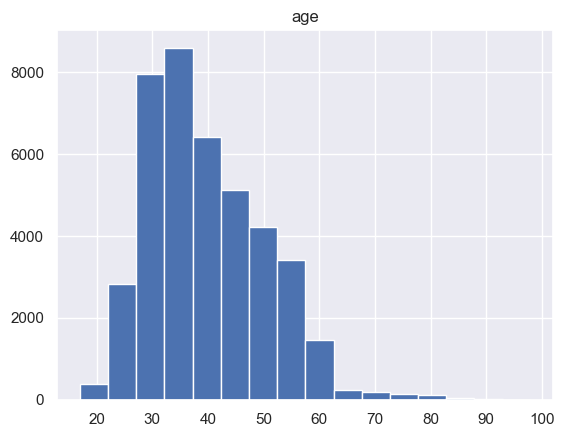

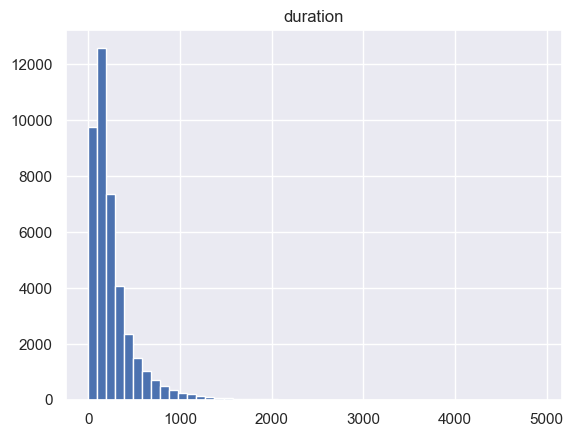

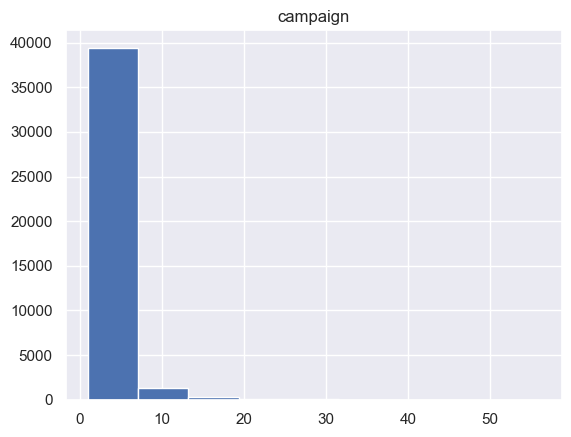

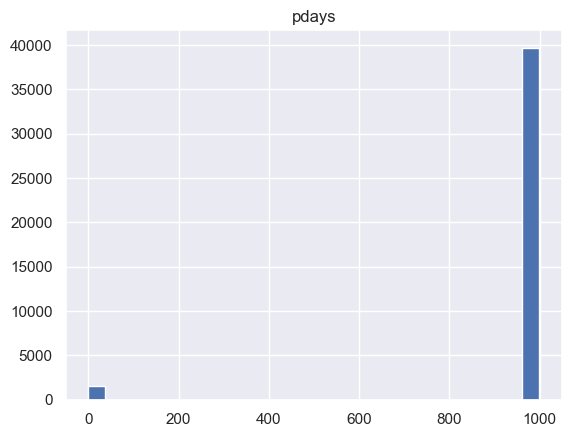

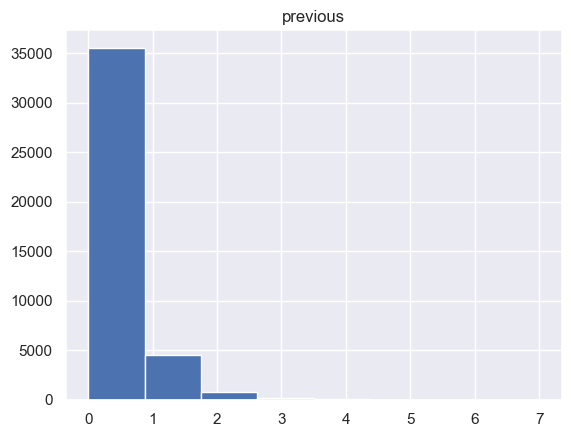

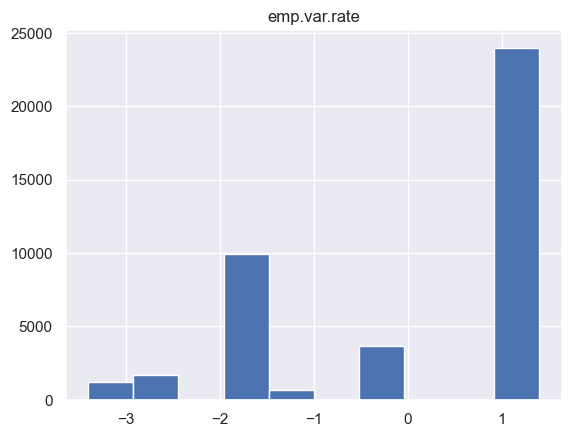

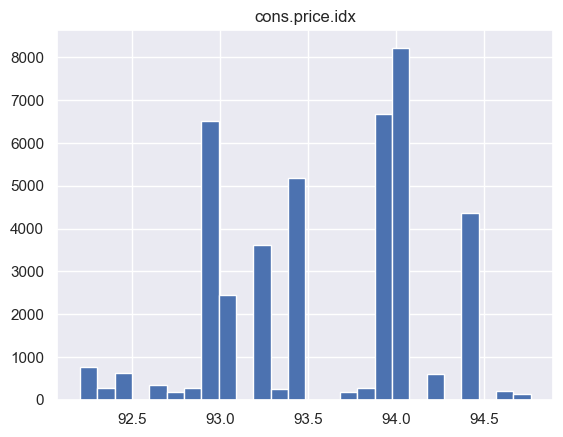

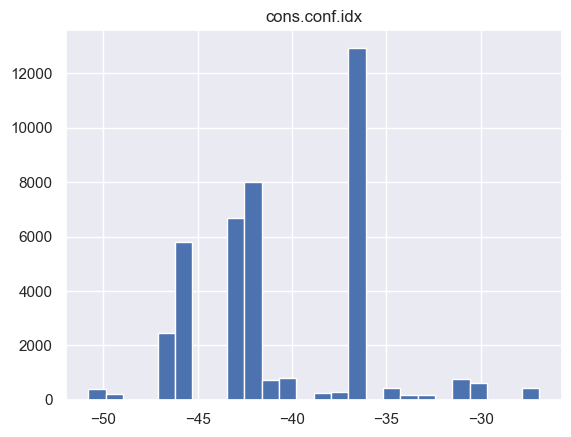

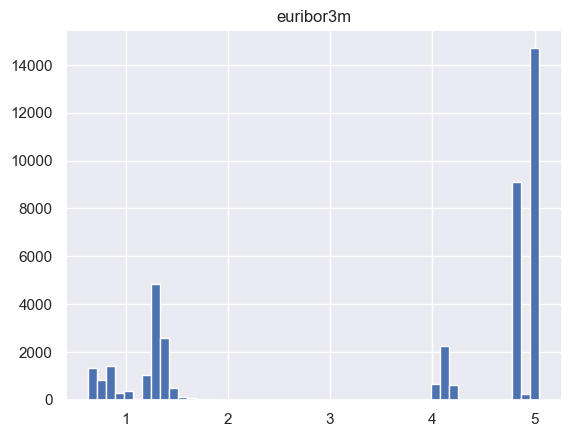

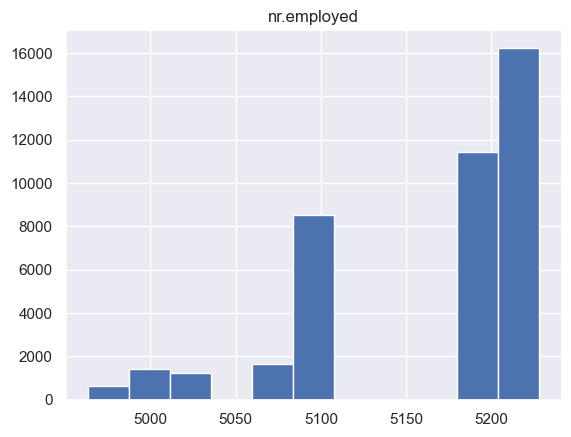

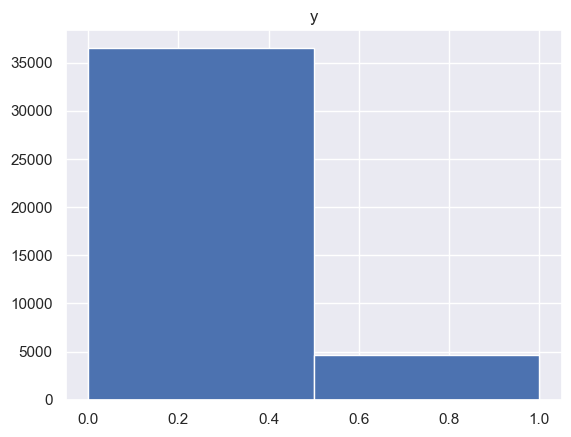

In [141]:
# Plot numeric distributions.
# Note: Macro-economic variables have lots of repeated values.

for col_name in bank_df.drop(columns = 'row_id').select_dtypes("number").columns:
    # Guestimate number of bins.
    bins = bank_df[col_name].nunique()
    bins = bins if bins < 30 else math.ceil(bins / 5)
    bins = bins if bins < 50 else 50

    fig, ax = plt.subplots()
    # Draw the histogram.
    ax.hist(bank_df[col_name], bins=bins, edgecolor="white")
    ax.set_title(col_name)

    plt.show()

In [ ]:
# Correlation between numerical features and target variable
(
    bank_df.select_dtypes("number")
    .corrwith(bank_df["y"])
    .rename("Correlation with target")
    .sort_values(ascending=False)
    .round(2)
    .to_frame()
)

,Correlation with target
y,1.00
duration,0.41
row_id,0.29
previous,0.23
cons.conf.idx,0.05
age,0.03
campaign,-0.07
cons.price.idx,-0.14
emp.var.rate,-0.30
euribor3m,-0.31


C:\Users\testadmin\AppData\Local\Temp\2\ipykernel_10352\1272626541.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col_name in bank_df.select_dtypes("object").columns:


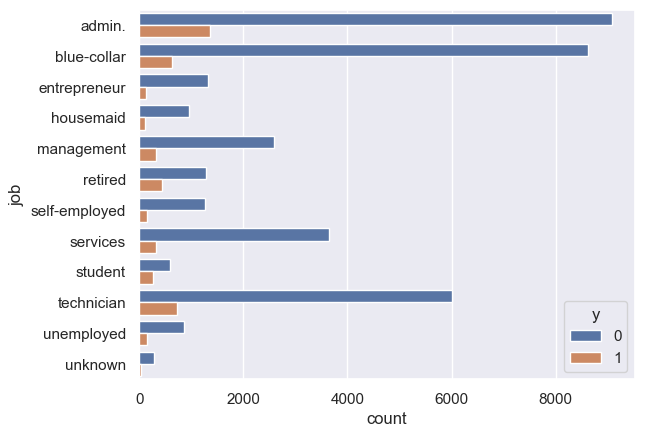

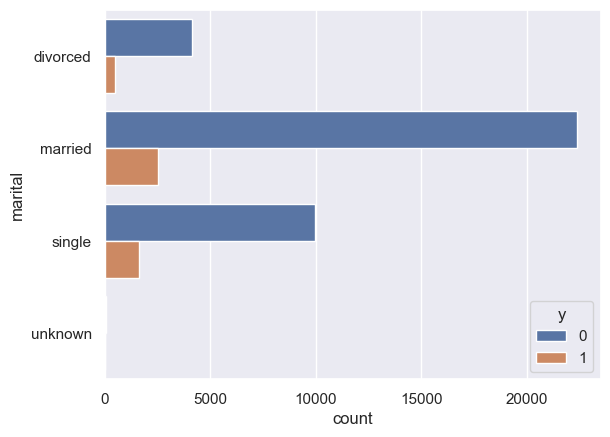

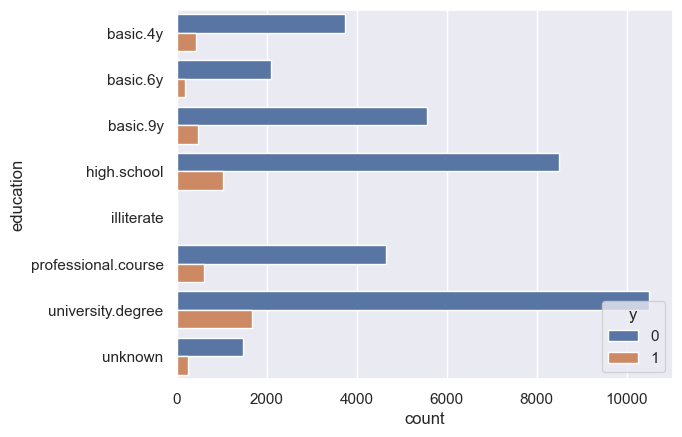

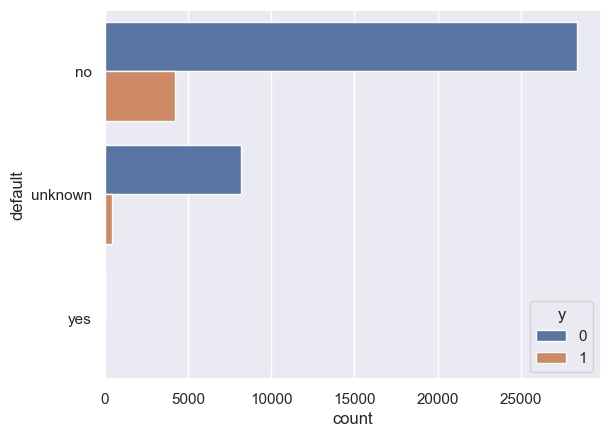

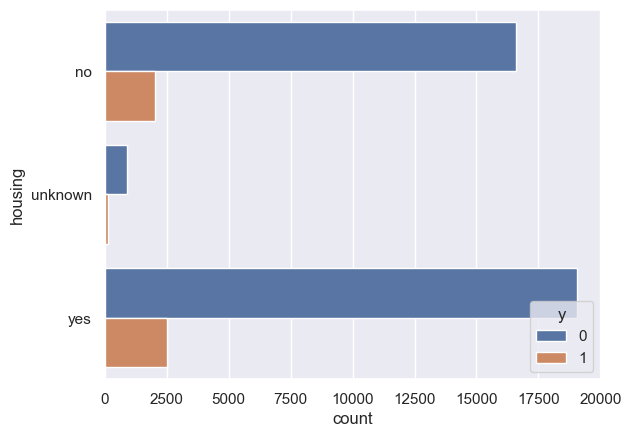

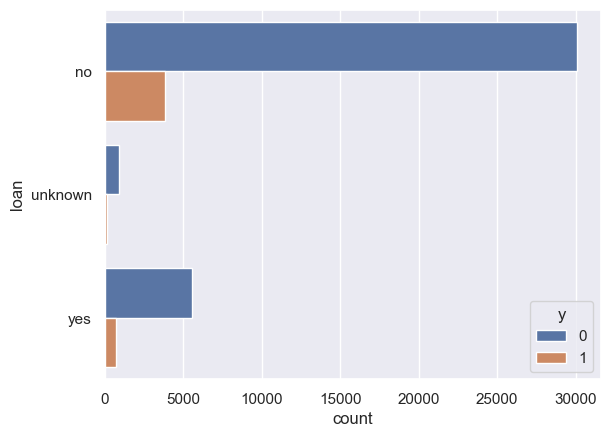

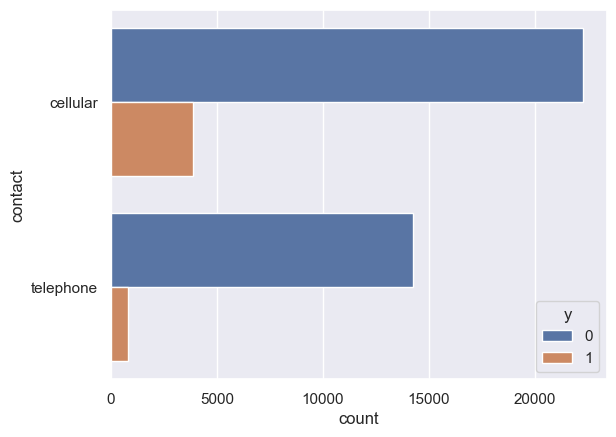

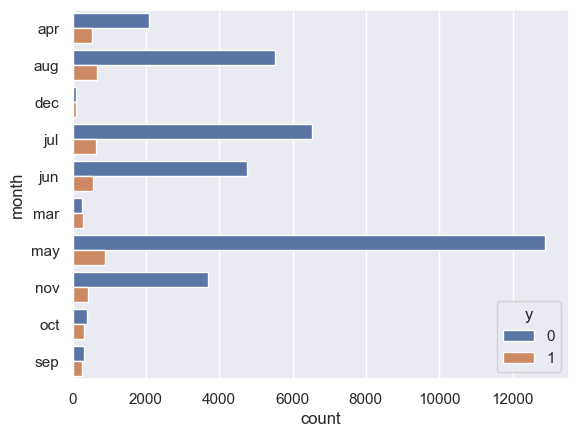

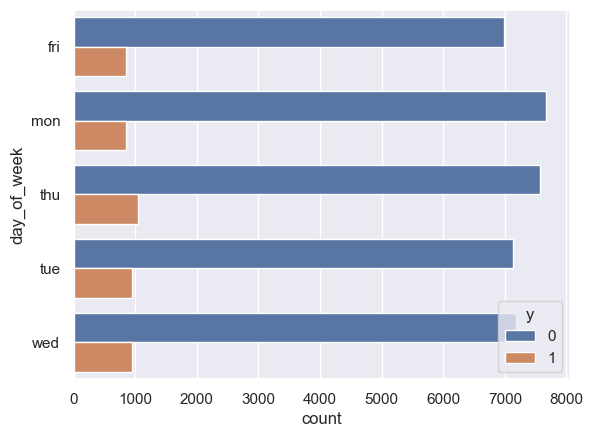

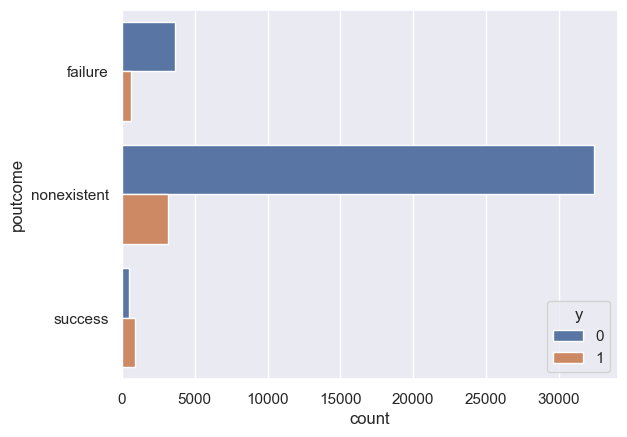

In [134]:
# Plot categorical distributions and relation to y

for col_name in bank_df.select_dtypes("object").columns:


    grouped_df = (    
        bank_df
        .groupby([col_name, 'y'], as_index = False)
        .agg(count = ('row_id', 'count'))
    )

    ax = sns.barplot(data=grouped_df, x="count", y=col_name, hue="y")
    ax.legend(title = "y", loc="lower right")

    plt.show()